# Lab assignment №1, part 3

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the third part of the assignment. First and second parts are waiting for you in the same directory.*__

##  Part 3. SVM and kernels

Kernels concept get adopted in variety of ML algorithms (e.g. Kernel PCA, Gaussian Processes, kNN, ...).

So in this task you are to examine kernels for SVM algorithm applied to rather simple artificial datasets.

To make it clear: we will work with the classification problem through the whole notebook. 

In [2]:
import warnings
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
plt.rcParams['figure.dpi'] = 100

Let's generate our dataset and take a look on it.

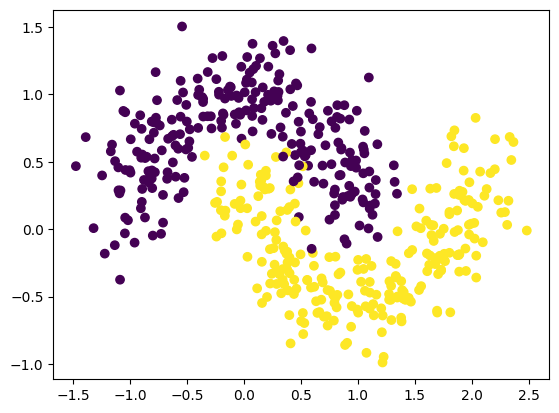

In [3]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=42)
plt.scatter(moons_points[:, 0], moons_points[:, 1], c=moons_labels)
plt.show()

## 1.1 Pure models.
First let's try to solve this case with good old Logistic Regression and simple (linear kernel) SVM classifier.

Train LR and SVM classifiers (choose params by hand, no CV or intensive grid search neeeded) and plot their decision regions. Calculate one preffered classification metric.

Describe results in one-two sentences.

_Tip:_ to plot classifiers decisions you colud use either sklearn examples ([this](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_alpha.html#sphx-glr-auto-examples-neural-networks-plot-mlp-alpha-py) or any other) and mess with matplotlib yourself or great [mlxtend](https://github.com/rasbt/mlxtend) package (see their examples for details)

_Pro Tip:_ wirte function `plot_decisions` taking a dataset and an estimator and plotting the results cause you want to use it several times below

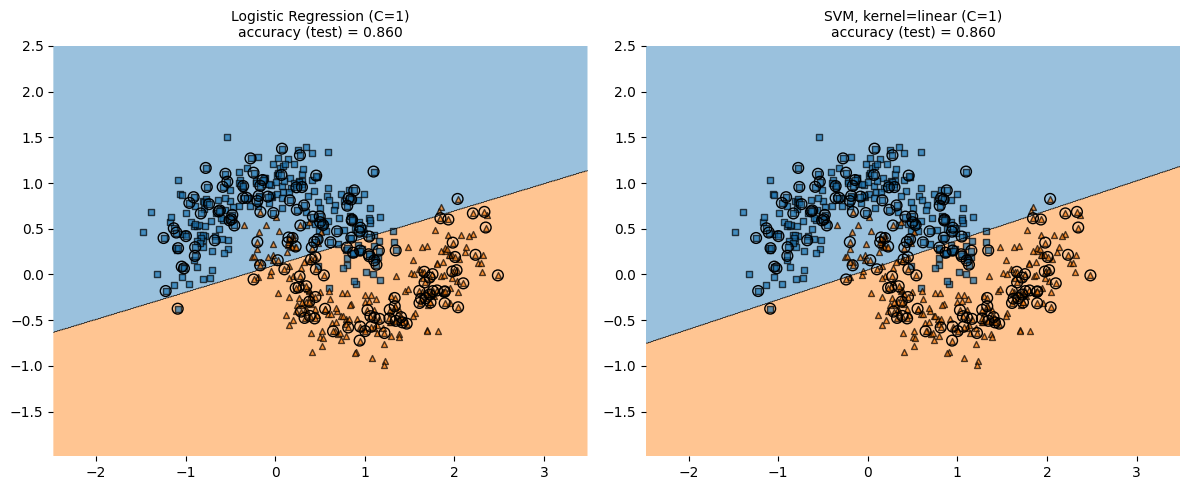

Коэффициенты LR: [[ 1.158 -3.901]]  | SVM: [[ 0.818 -2.517]]
C =   0.01: LR acc = 0.820, linear SVM acc = 0.827
C =    0.1: LR acc = 0.840, linear SVM acc = 0.860
C =      1: LR acc = 0.860, linear SVM acc = 0.860
C =     10: LR acc = 0.847, linear SVM acc = 0.853
C =    100: LR acc = 0.847, linear SVM acc = 0.853


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.base import clone

from mlxtend.plotting import plot_decision_regions

# Качество оцениваем на отложенной выборке (30%), иначе метрика покажет запоминание, а не обобщение.
# Метрика — accuracy: классы сбалансированы (250/250), ошибки обоих типов одинаково важны.
X_tr, X_te, y_tr, y_te = train_test_split(moons_points, moons_labels, test_size=0.3,
                                          random_state=RANDOM_STATE, stratify=moons_labels)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def plot_decisions(X, y, estimator, title='', ax=None, X_test=None, y_test=None):
    # Обучает estimator на (X, y), рисует области решений и возвращает accuracy на test.
    # На графике все точки (train + test); тестовые обведены кружками.
    estimator.fit(X, y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    score, X_all, y_all, highlight = None, X, y, None
    if X_test is not None:
        score = accuracy_score(y_test, estimator.predict(X_test))
        X_all, y_all, highlight = np.vstack([X, X_test]), np.concatenate([y, y_test]), X_test
        title = f'{title}\naccuracy (test) = {score:.3f}'
    plot_decision_regions(X_all, y_all, clf=estimator, ax=ax, legend=0, X_highlight=highlight,
                          scatter_kwargs={'s': 18, 'alpha': 0.7},
                          scatter_highlight_kwargs={'s': 60, 'c': 'none', 'edgecolor': 'k'})
    ax.set_title(title, fontsize=10)
    return score


RESULTS = {}

lr = LogisticRegression(C=1.0)          # C=1 — умеренная регуляризация; данные двумерные, масштаб ~1, scaler не нужен
svm = SVC(kernel='linear', C=1.0)       # линейное ядро; C=1 — стандартный компромисс между шириной зазора и ошибками

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RESULTS['LogReg'] = plot_decisions(X_tr, y_tr, lr, 'Logistic Regression (C=1)', axes[0], X_te, y_te)
RESULTS['SVM linear'] = plot_decisions(X_tr, y_tr, svm, 'SVM, kernel=linear (C=1)', axes[1], X_te, y_te)
plt.tight_layout(); plt.show()

print('Коэффициенты LR:', np.round(lr.coef_, 3), ' | SVM:', np.round(svm.coef_, 3))
for C_ in [0.01, 0.1, 1, 10, 100]:
    a_lr = accuracy_score(y_te, LogisticRegression(C=C_).fit(X_tr, y_tr).predict(X_te))
    a_svm = accuracy_score(y_te, SVC(kernel='linear', C=C_).fit(X_tr, y_tr).predict(X_te))
    print(f'C = {C_:>6}: LR acc = {a_lr:.3f}, linear SVM acc = {a_svm:.3f}')

**Выбор метрики:** accuracy. 
Классы сбалансированы (250/250), и ошибки обоих типов одинаково важны. Качество считаем на отложенных 30% данных (на графиках тестовые точки обведены кружками).

**Вывод.** Обе модели строят прямую и дают одинаковую accuracy ≈ **0.86**. Прямые почти совпадают (у LR и SVM разные функции потерь, но на этих данных оптимальная разделяющая прямая практически одна). Ошибки сосредоточены там, где «рога» одного полумесяца заходят в другой. Это потолок линейной модели: изменение `C` от 0.01 до 100 меняет accuracy лишь в пределах 0.82–0.86, то есть проблема в смещении (форма границы), а не в регуляризации.

## 1.2 Kernel tirck

Now use different kernels (`poly`, `rbf`, `sigmoid`) on SVC to get better results. Play `degree` parameter and others.

For each kernel estimate optimal params, plot decision regions, calculate metric you've chosen eariler.

Write couple of sentences on:

* What have happenned with classification quality?
* How did decision border changed for each kernel?
* What `degree` have you chosen and why?

poly     лучшие параметры: {'C': 10, 'coef0': 1, 'degree': 6, 'gamma': 'scale'}, CV acc = 0.986
rbf      лучшие параметры: {'C': 10, 'gamma': 1}, CV acc = 0.980
sigmoid  лучшие параметры: {'C': 100, 'coef0': -1, 'gamma': 0.3}, CV acc = 0.974


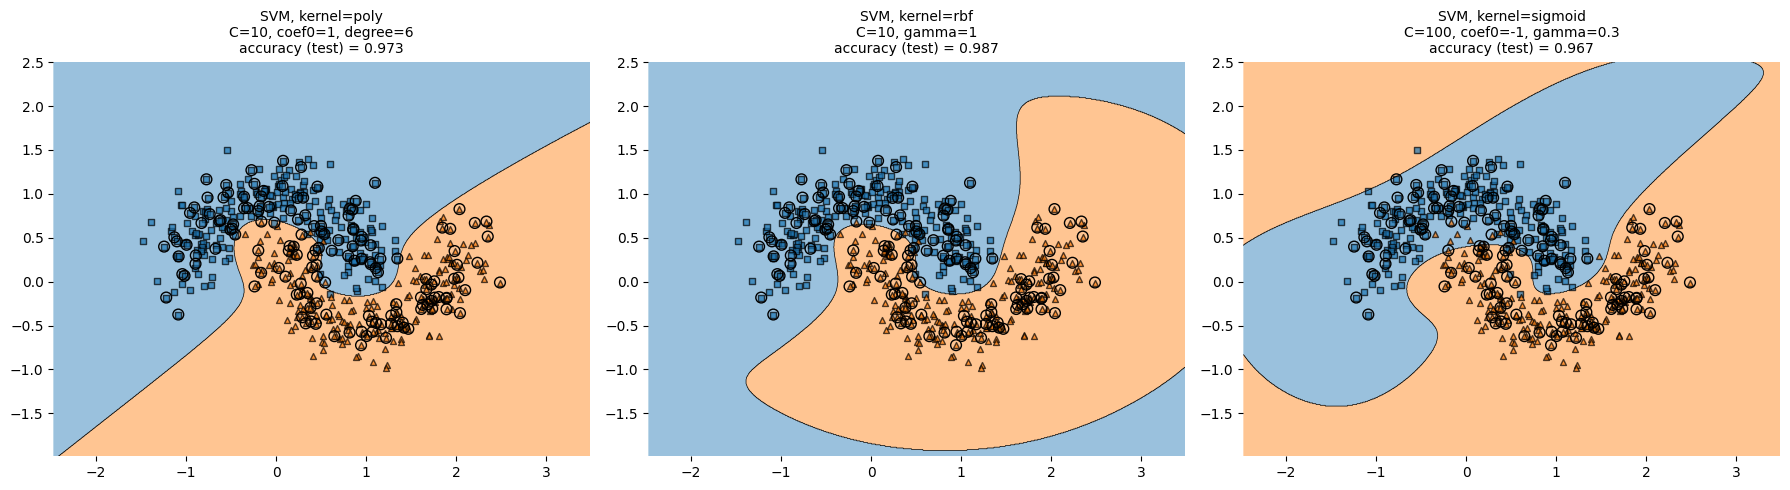

In [6]:
# Для каждого ядра подбираем параметры небольшой сеткой с 5-fold CV на train.
# StandardScaler перед SVC: ядра rbf/poly/sigmoid зависят от масштаба признаков через gamma.
def svc_pipe(**kw):
    return make_pipeline(StandardScaler(), SVC(**kw))

grids = {
    'poly': {'svc__degree': [1, 2, 3, 4, 5, 6, 7], 'svc__coef0': [0, 1],
             'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale']},
    'rbf': {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.1, 0.3, 1, 3, 10]},
    'sigmoid': {'svc__C': [0.01, 0.1, 1, 10, 100], 'svc__gamma': [0.01, 0.1, 0.3, 1], 'svc__coef0': [-1, 0, 1]},
}
searches = {}
for kernel, grid in grids.items():
    s = GridSearchCV(svc_pipe(kernel=kernel), grid, cv=CV, scoring='accuracy', n_jobs=-1).fit(X_tr, y_tr)
    searches[kernel] = s
    print(f'{kernel:8s} лучшие параметры: { {k.replace("svc__", ""): v for k, v in s.best_params_.items()} }, '
          f'CV acc = {s.best_score_:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (kernel, s) in zip(axes, searches.items()):
    params = ', '.join(f'{k.replace("svc__", "")}={v}' for k, v in s.best_params_.items() if k != 'svc__gamma' or kernel != 'poly')
    label = f'SVM {kernel}' + (' (лучший по сетке)' if kernel == 'poly' else '')
    RESULTS[label] = plot_decisions(X_tr, y_tr, s.best_estimator_, f'SVM, kernel={kernel}\n{params}', ax, X_te, y_te)
plt.tight_layout(); plt.show()

Посмотрим подробнее, как степень полиномиального ядра влияет на качество и форму границы.

Лучшая CV accuracy для каждой степени (максимум по C):
coef0       0      1
degree              
1       0.863  0.863
2       0.503  0.857
3       0.877  0.980
4       0.523  0.983
5       0.883  0.983
6       0.543  0.986
7       0.897  0.983


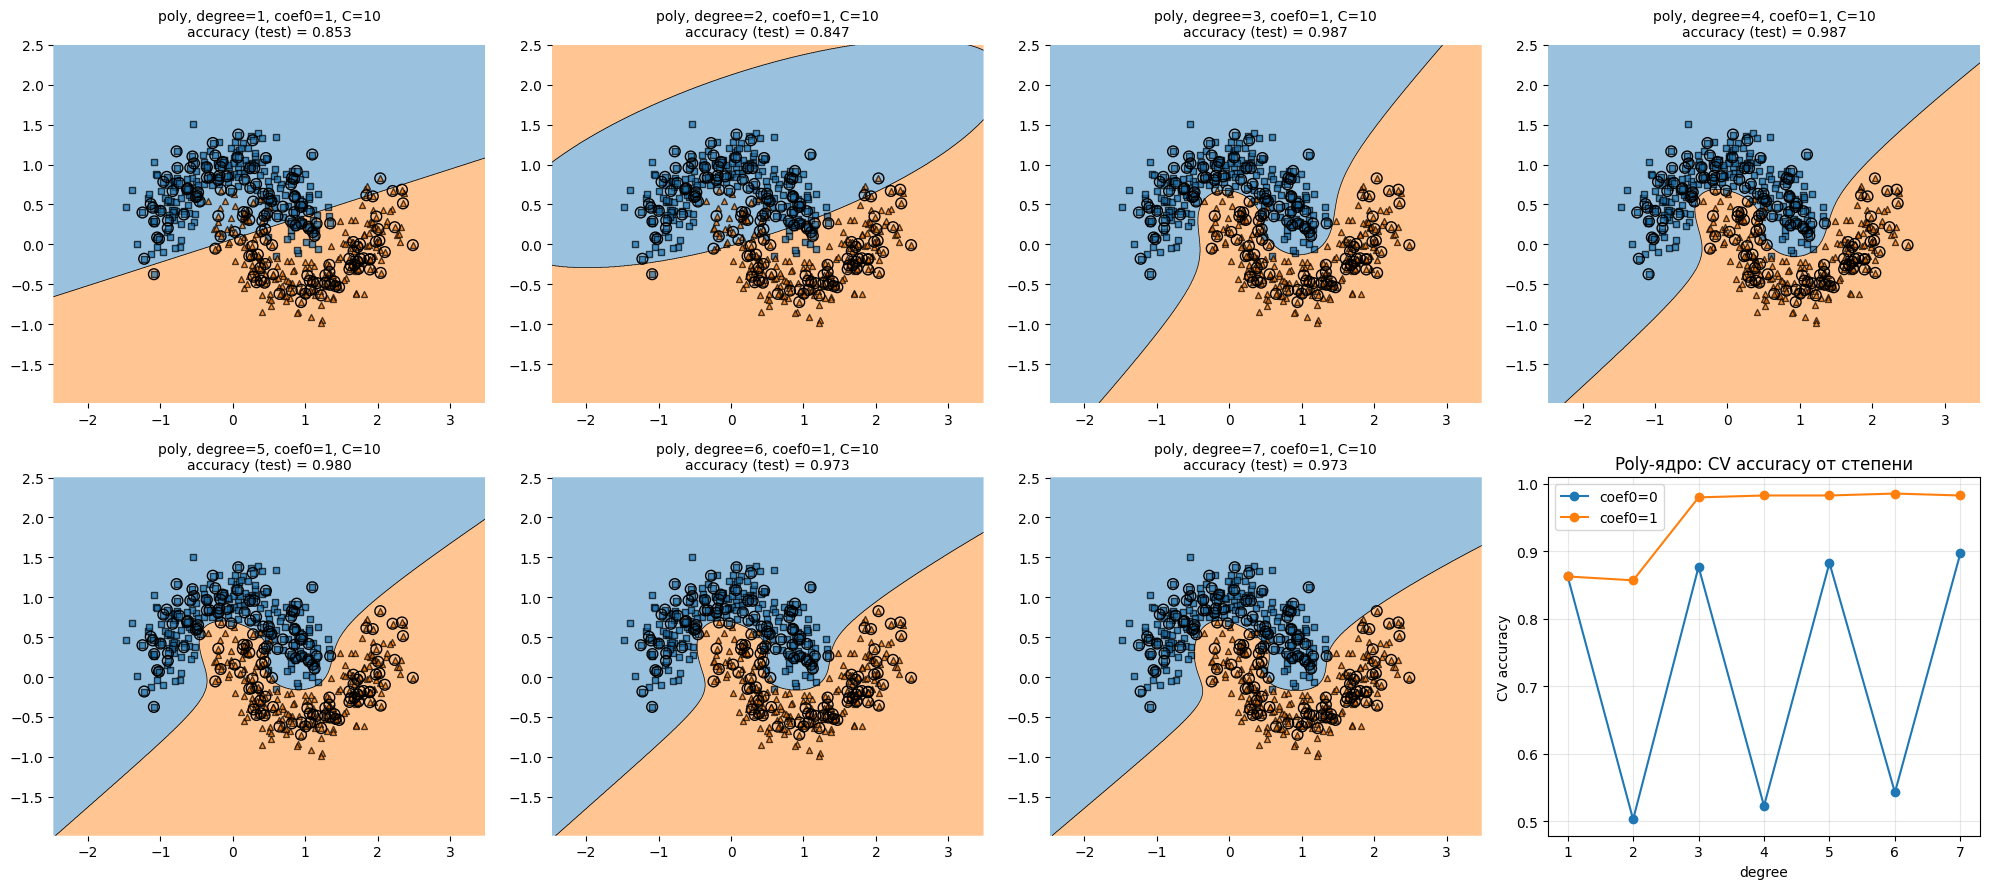


Выбранная модель: poly, degree=3, coef0=1, C=10; CV acc = 0.980, test acc = 0.987


In [7]:
res = pd.DataFrame(searches['poly'].cv_results_)
res['degree'] = [p['svc__degree'] for p in res['params']]
res['coef0'] = [p['svc__coef0'] for p in res['params']]
best_by_degree = res.groupby(['degree', 'coef0'])['mean_test_score'].max().unstack()
print('Лучшая CV accuracy для каждой степени (максимум по C):')
print(best_by_degree.round(3).to_string())

best_C = searches['poly'].best_params_['svc__C']
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, degree in zip(axes.ravel(), range(1, 8)):
    model = svc_pipe(kernel='poly', degree=degree, coef0=1, C=best_C)
    plot_decisions(X_tr, y_tr, model, f'poly, degree={degree}, coef0=1, C={best_C}', ax, X_te, y_te)
ax = axes.ravel()[-1]
for coef0 in [0, 1]:
    ax.plot(best_by_degree.index, best_by_degree[coef0], 'o-', label=f'coef0={coef0}')
ax.set_xlabel('degree'); ax.set_ylabel('CV accuracy'); ax.set_title('Poly-ядро: CV accuracy от степени')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Выбранная степень (обоснование в выводе ниже): минимальная степень, на которой CV accuracy выходит на плато
CHOSEN_DEG = 3
svm_poly_chosen = svc_pipe(kernel='poly', degree=CHOSEN_DEG, coef0=1, C=best_C)
RESULTS[f'SVM poly (degree={CHOSEN_DEG}, выбранная)'] = accuracy_score(y_te, svm_poly_chosen.fit(X_tr, y_tr).predict(X_te))
print(f'\nВыбранная модель: poly, degree={CHOSEN_DEG}, coef0=1, C={best_C}; '
      f'CV acc = {best_by_degree.loc[CHOSEN_DEG, 1]:.3f}, test acc = {RESULTS[f"SVM poly (degree={CHOSEN_DEG}, выбранная)"]:.3f}')

**Что произошло с качеством.** Нелинейные ядра решают задачу: accuracy на test выросла с 0.86 до **~0.98** Оставшиеся ошибки — точки, которые из-за шума (`noise=0.2`) лежат глубоко внутри чужого полумесяца. Их не стоит пытаться классифицировать правильно, иначе граница начнёт переобучаться.

**Как меняется граница:**
- **poly** — гладкая S-образная кривая, которая огибает рога полумесяцев. Вдали от данных она уходит в бесконечность как полином, то есть экстраполяция за пределы данных определяется старшей степенью, а не данными.
- **rbf** — граница *локальная*: решение зависит от расстояния до опорных векторов, поэтому вдали от данных функция затухает и граница замыкается в петлю вокруг облака точек. Это самая гибкая и устойчивая граница здесь.
- **sigmoid** — тоже нелинейная граница, хорошо работающая около данных, но вдали от них появляются странные области (полоса оранжевого класса в левом верхнем углу). Сигмоидное ядро не является положительно определённым (не удовлетворяет условию Мерсера при всех параметрах), и SVM с ним работает нестабильно. Сетка это подтверждает: медианная CV accuracy по сетке ≈ 0.84, и лишь ~2% комбинаций параметров дают ≥ 0.95. Хороший результат здесь — удачный подбор `coef0=-1, gamma=0.3, C=100`.

**Какая степень выбрана и почему: `degree = 3` (с `coef0 = 1`).**
- График CV accuracy от степени показывает: степени 1–2 недостаточно (~0.86, граница — прямая или эллипс/гипербола), а начиная с 3 качество выходит на плато ≈0.98. По сетке формально лучшая степень 6 (CV 0.986 против 0.980), но разница в 0.006 — это ≈2 объекта из 350, то есть шум. Из моделей с одинаковым качеством берём самую простую: при росте степени граница становится более изогнутой и хуже экстраполирует, а риск переобучения растёт. Степень 3 — минимальная, при которой полином может описать S-образную границу (полином 2-й степени задаёт только конику). На test степень 3 даже лучше: 0.987 против 0.973.
- **Важен `coef0`.** При `coef0 = 0` ядро $(\gamma\, x^Tz)^d$ однородное и содержит только мономы степени ровно $d$. Для чётных $d$ получаем 0.5, то есть случайное угадывание. Причина в том, что полумесяцы из `make_moons` центрально симметричны: второй класс — отражение первого относительно центра $(0.5,\,0.25)$, а после `StandardScaler` центр переходит в начало координат. Для чётного однородного ядра $f(-x) = f(x)$, поэтому точка и её отражение всегда получают одинаковый класс, и модель не может их различить. При `coef0 = 1` в ядро входят все мономы степени от 0 до $d$, и эта проблема исчезает.

## 1.3 Simpler solution (of a kind)
What is we could use Logisitc Regression to successfully solve this task?

Feature generation is a thing to help here. Different techniques of feature generation are used in real life, couple of them will be covered in additional lectures.

In particular case simple `PolynomialFeatures` ([link](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)) are able to save the day.

Generate the set of new features, train LR on it, plot decision regions, calculate metric.

* Comare SVM's results with this solution (quality, borders type)
* What degree of PolynomialFeatures have you used? Compare with same SVM kernel parameter.

In [8]:
from sklearn.preprocessing import PolynomialFeatures

# LR на полиномиальных признаках: PolynomialFeatures -> StandardScaler -> LogisticRegression.
# Масштабирование после генерации признаков обязательно: x^5 и x на разных масштабах мешают регуляризации и сходимости.
def poly_lr(degree, C=1.0):
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(),
                         LogisticRegression(C=C, max_iter=5000))

poly_search = GridSearchCV(poly_lr(3), {'polynomialfeatures__degree': list(range(1, 11)),
                                        'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
                           cv=CV, scoring='accuracy', n_jobs=-1).fit(X_tr, y_tr)
print('Лучшие параметры:', poly_search.best_params_, f'| CV acc = {poly_search.best_score_:.3f}')

res = pd.DataFrame(poly_search.cv_results_)
res['degree'] = [p['polynomialfeatures__degree'] for p in res['params']]
cv_by_deg = res.groupby('degree')['mean_test_score'].max()
print('Лучшая CV accuracy по степени:', cv_by_deg.round(3).to_dict())

Лучшие параметры: {'logisticregression__C': 100, 'polynomialfeatures__degree': 3} | CV acc = 0.980
Лучшая CV accuracy по степени: {1: 0.86, 2: 0.863, 3: 0.98, 4: 0.977, 5: 0.977, 6: 0.977, 7: 0.977, 8: 0.974, 9: 0.974, 10: 0.974}


Число признаков после PolynomialFeatures(degree=3): 9


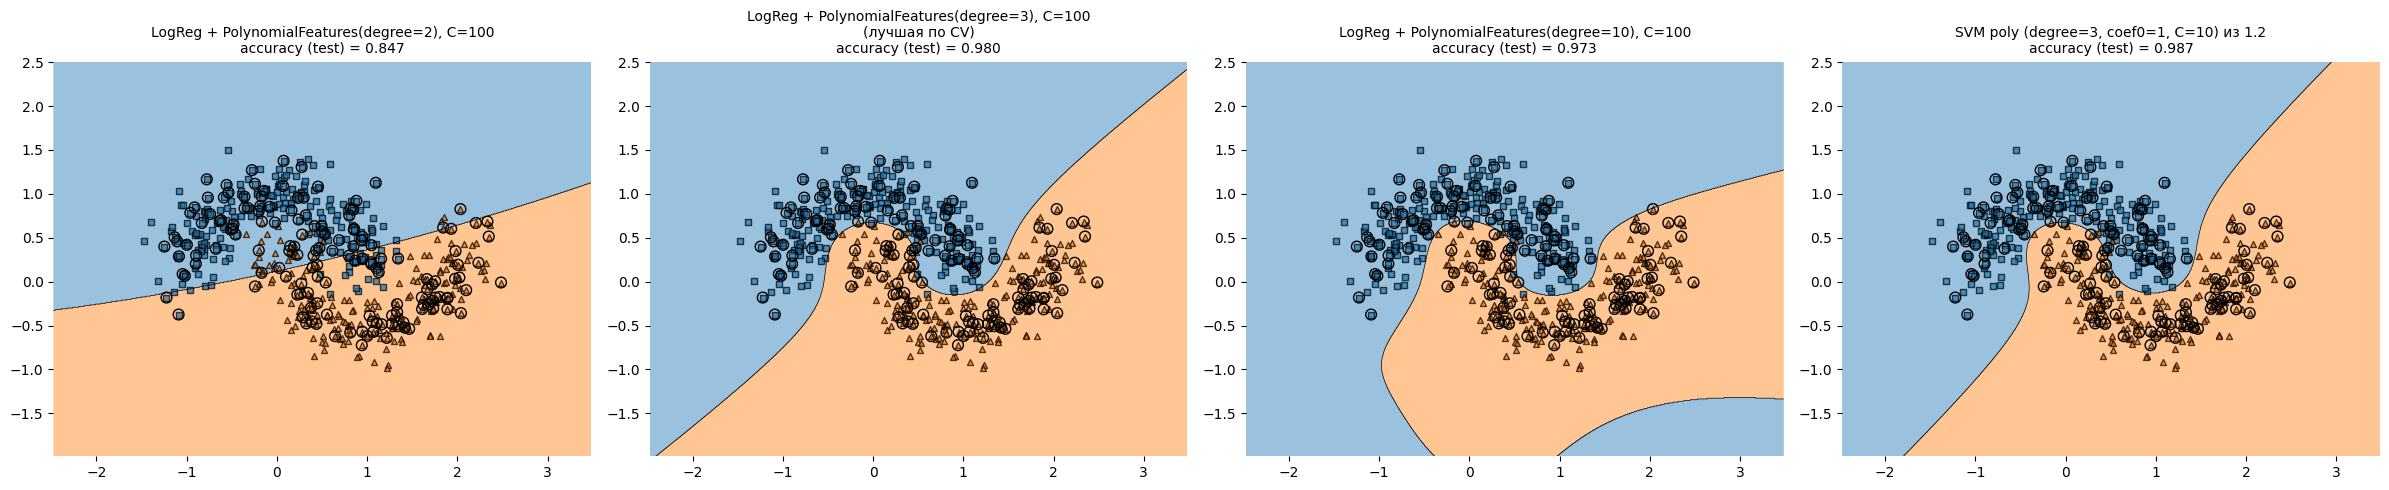

LogReg                            0.860
SVM linear                        0.860
SVM poly (лучший по сетке)        0.973
SVM rbf                           0.987
SVM sigmoid                       0.967
SVM poly (degree=3, выбранная)    0.987
LogReg + Poly(deg=3)              0.980


In [9]:
BEST_POLY_DEG = poly_search.best_params_['polynomialfeatures__degree']
BEST_POLY_C = poly_search.best_params_['logisticregression__C']
n_feat = PolynomialFeatures(BEST_POLY_DEG, include_bias=False).fit(X_tr).n_output_features_
print(f'Число признаков после PolynomialFeatures(degree={BEST_POLY_DEG}): {n_feat}')

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
plot_decisions(X_tr, y_tr, poly_lr(2, BEST_POLY_C),
               f'LogReg + PolynomialFeatures(degree=2), C={BEST_POLY_C}', axes[0], X_te, y_te)
RESULTS[f'LogReg + Poly(deg={BEST_POLY_DEG})'] = plot_decisions(
    X_tr, y_tr, poly_lr(BEST_POLY_DEG, BEST_POLY_C),
    f'LogReg + PolynomialFeatures(degree={BEST_POLY_DEG}), C={BEST_POLY_C}\n(лучшая по CV)', axes[1], X_te, y_te)
plot_decisions(X_tr, y_tr, poly_lr(10, BEST_POLY_C),
               f'LogReg + PolynomialFeatures(degree=10), C={BEST_POLY_C}', axes[2], X_te, y_te)
plot_decisions(X_tr, y_tr, svc_pipe(kernel='poly', degree=CHOSEN_DEG, coef0=1, C=best_C),
               f'SVM poly (degree={CHOSEN_DEG}, coef0=1, C={best_C}) из 1.2', axes[3], X_te, y_te)
plt.tight_layout(); plt.show()

print(pd.Series(RESULTS, name='accuracy (test)').round(3).to_string())

**Вывод.** Логистическая регрессия на полиномиальных признаках решает задачу так же хорошо, как SVM с ядром.

* **Качество:** лучшая по CV степень — **3** (9 признаков: $x_1, x_2, x_1^2, x_1x_2, x_2^2, x_1^3, \dots, x_2^3$), accuracy на test = **0.98**, против ~0.987 у SVM poly степени 3, то есть модели равноценны.
* **Форма границы:** у LR с degree = 3 и у SVM с полиномиальным ядром степени 3 S-образные границы практически одинаковые. Это ожидаемо: ядро $(\gamma\,x^Tz + 1)^3$ — это скалярное произведение в пространстве всех мономов степени ≤ 3, то есть ровно в том пространстве, которое `PolynomialFeatures(3)` строит явно (отличаются только весовые коэффициенты при мономах). Модели отличаются функцией потерь (logistic loss против hinge loss) и тем, что SVM опирается только на опорные векторы, но класс разделяющих поверхностей один и тот же.
* **Сравнение степеней:** в обоих подходах степени 2 мало (~0.85), степень 3 — минимально достаточная, и **совпадает с выбранной степенью ядра SVM**. При degree = 10 (65 признаков) качество на test немного падает (~0.973), а граница становится причудливой вдали от данных (отдельная капля синего класса справа внизу). Это переобучение и плохая экстраполяция высоких степеней.
* **Чем полезен kernel trick:** для 2 признаков явная генерация мономов дешёвая. Но число признаков растёт как $\binom{n+d}{d}$. Ядро вычисляет то же скалярное произведение за $O(n)$, не строя признаки явно, а rbf-ядру соответствует вообще бесконечномерное пространство признаков.

## 1.4 Harder problem

Let's make this task a bit more challenging via upgrading dataset:

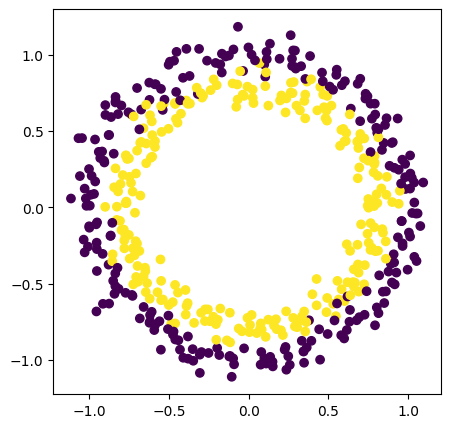

In [10]:
from sklearn.datasets import make_circles

circles_points, circles_labels = make_circles(n_samples=500, noise=0.06, random_state=42)

plt.figure(figsize=(5, 5))
plt.scatter(circles_points[:, 0], circles_points[:, 1], c=circles_labels)
plt.show()

And even more:

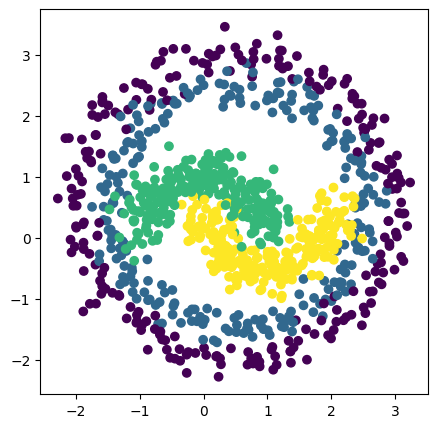

In [11]:
points = np.vstack((circles_points*2.5 + 0.5, moons_points))
labels = np.hstack((circles_labels, moons_labels + 2)) # + 2 to distinct moons classes

plt.figure(figsize=(5, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels)
plt.show()

Now do your best using all the approaches above!

Tune LR with generated features, SVM with appropriate kernel of your choice. You may add some of your loved models to demonstrate their (and your) strength. Again plot decision regions, calculate metric.

Justify the results in a few phrases.

In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# 4 сбалансированных класса по 250 точек -> accuracy по-прежнему адекватная метрика
print('Размер классов:', np.bincount(labels))
P_tr, P_te, l_tr, l_te = train_test_split(points, labels, test_size=0.3,
                                          random_state=RANDOM_STATE, stratify=labels)

candidates = {
    'LogReg (линейная)': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                          {'logisticregression__C': [0.1, 1, 10]}),
    'LogReg + PolynomialFeatures': (poly_lr(3),
                                    {'polynomialfeatures__degree': [2, 3, 4, 5, 6, 7, 8],
                                     'logisticregression__C': [0.1, 1, 10, 100]}),
    'SVM rbf': (svc_pipe(kernel='rbf'),
                {'svc__C': [0.1, 1, 10, 100, 1000], 'svc__gamma': [0.1, 0.3, 1, 3, 10]}),
    'SVM poly': (svc_pipe(kernel='poly', coef0=1),
                 {'svc__degree': [2, 3, 4, 5, 6], 'svc__C': [0.1, 1, 10, 100]}),
    'kNN': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {'kneighborsclassifier__n_neighbors': [1, 3, 5, 7, 11, 15, 21, 31],
             'kneighborsclassifier__weights': ['uniform', 'distance']}),
    'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
                      {'min_samples_leaf': [1, 3, 5, 10]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {'n_estimators': [100, 300], 'max_depth': [2, 3], 'learning_rate': [0.05, 0.1]}),
    'MLP': (make_pipeline(StandardScaler(), MLPClassifier(max_iter=3000, random_state=RANDOM_STATE)),
            {'mlpclassifier__hidden_layer_sizes': [(32,), (64, 64)], 'mlpclassifier__alpha': [1e-4, 1e-2, 1e-1]}),
}

hard_searches, rows = {}, []
for name, (model, grid) in candidates.items():
    s = GridSearchCV(model, grid, cv=CV, scoring='accuracy', n_jobs=-1).fit(P_tr, l_tr)
    hard_searches[name] = s
    rows.append({'model': name, 'CV accuracy': s.best_score_,
                 'test accuracy': accuracy_score(l_te, s.predict(P_te)),
                 'best params': {k.split('__')[-1]: v for k, v in s.best_params_.items()}})

hard_table = pd.DataFrame(rows).sort_values('CV accuracy', ascending=False).reset_index(drop=True)
pd.set_option('display.max_colwidth', 120)
hard_table.round(3)

Размер классов: [250 250 250 250]


,model,CV accuracy,test accuracy,best params
0,SVM rbf,0.927,0.923,"{'C': 10, 'gamma': 1}"
1,SVM poly,0.927,0.910,"{'C': 100, 'degree': 3}"
2,MLP,0.927,0.930,"{'alpha': 0.0001, 'hidden_layer_sizes': (32,)}"
3,LogReg + PolynomialFeatures,0.921,0.913,"{'C': 100, 'degree': 7}"
4,kNN,0.911,0.877,"{'n_neighbors': 3, 'weights': 'uniform'}"
5,Random Forest,0.889,0.900,{'min_samples_leaf': 1}
6,Gradient Boosting,0.876,0.890,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}"
7,LogReg (линейная),0.386,0.417,{'C': 0.1}


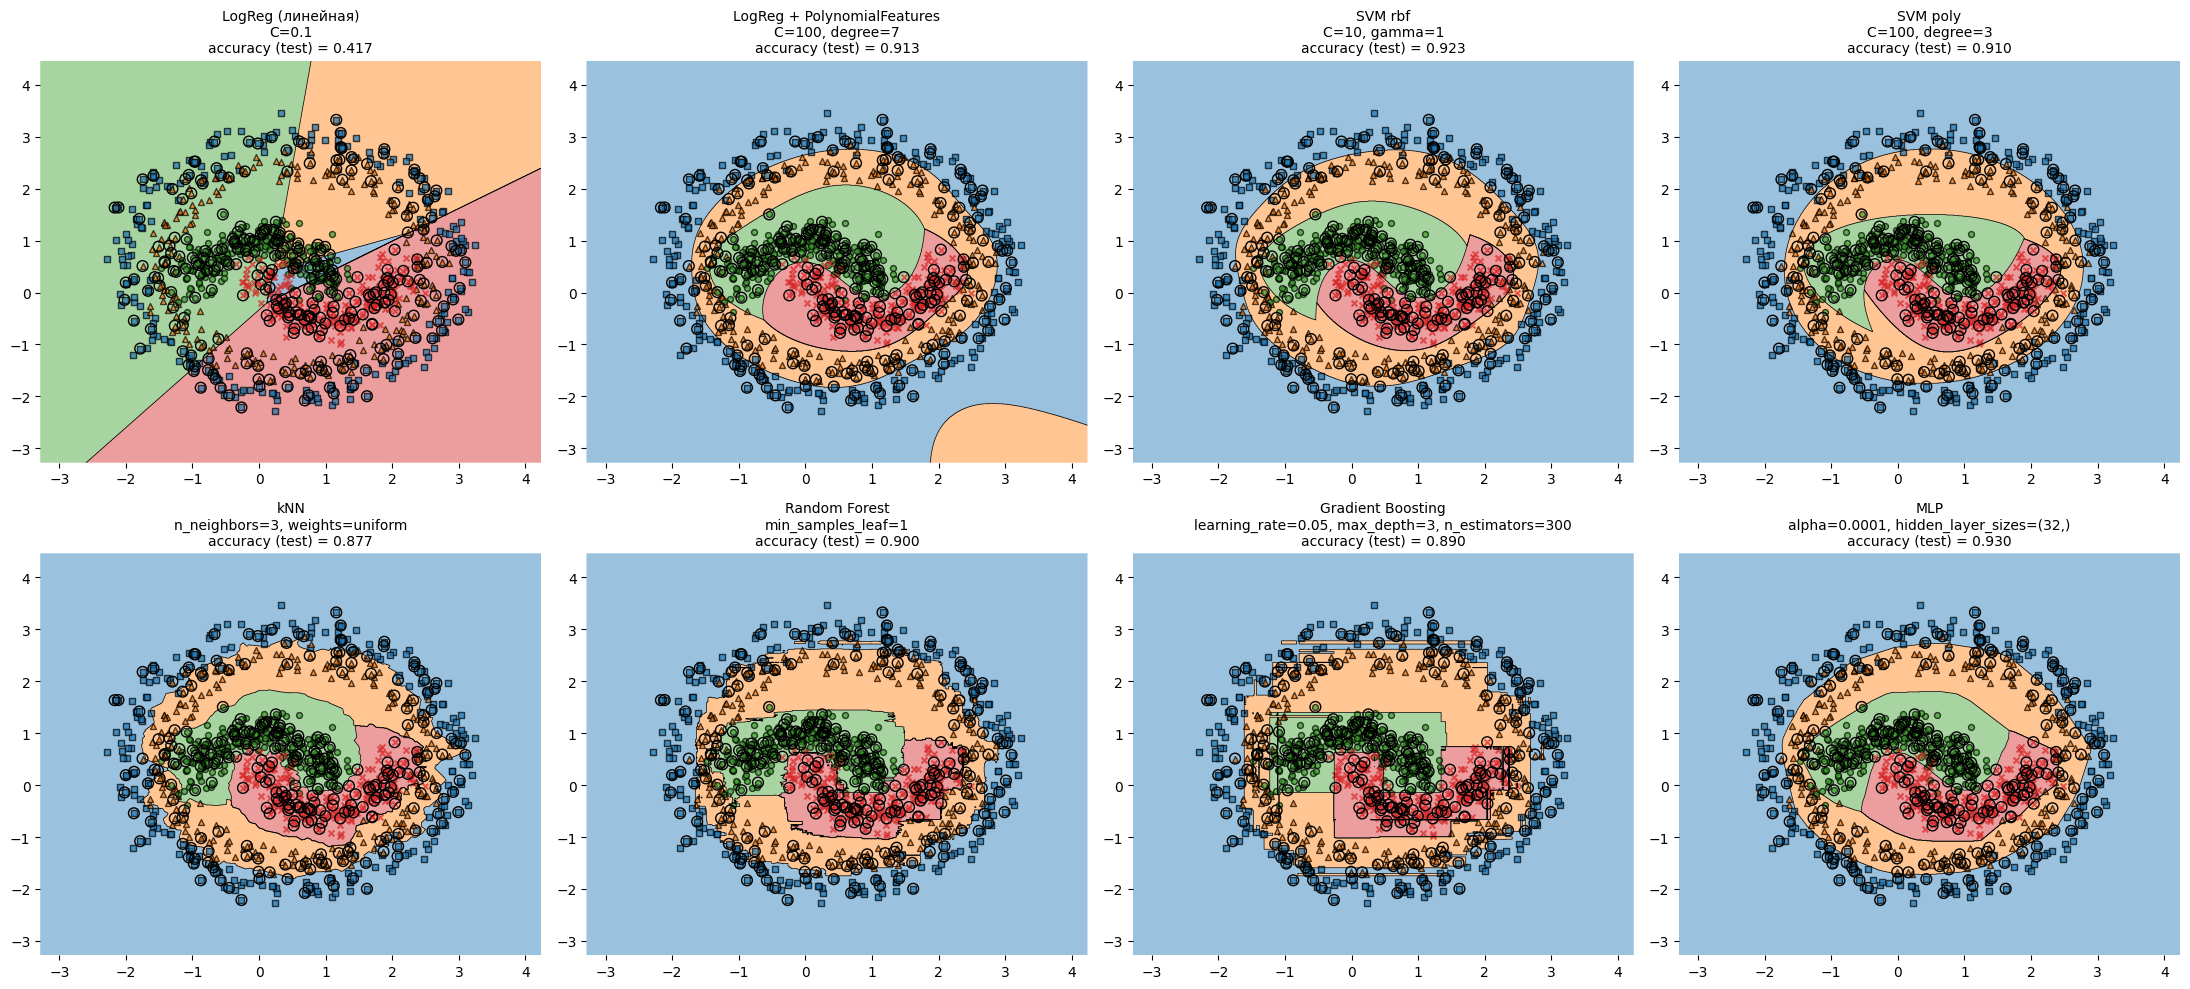

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, (name, s) in zip(axes.ravel(), hard_searches.items()):
    params = ', '.join(f'{k.split("__")[-1]}={v}' for k, v in s.best_params_.items())
    plot_decisions(P_tr, l_tr, clone(s.best_estimator_), f'{name}\n{params}', ax, P_te, l_te)
plt.tight_layout(); plt.show()

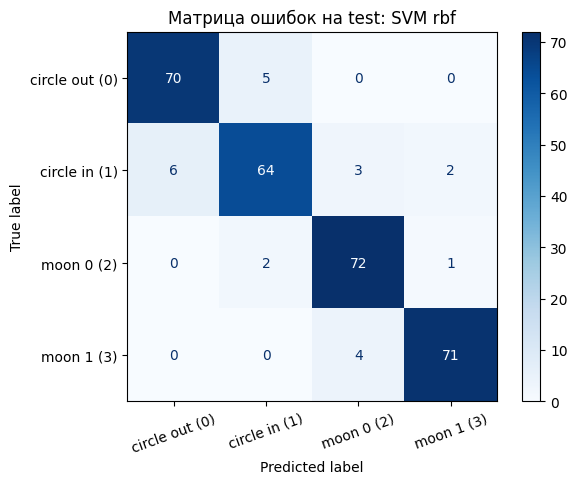

In [14]:
# Какие классы путает лучшая по CV модель
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_name = hard_table.loc[0, 'model']
cm = confusion_matrix(l_te, hard_searches[best_name].predict(P_te))
ConfusionMatrixDisplay(cm, display_labels=['circle out (0)', 'circle in (1)', 'moon 0 (2)', 'moon 1 (3)']).plot(cmap='Blues')
plt.title(f'Матрица ошибок на test: {best_name}'); plt.xticks(rotation=20); plt.show()

**Результаты** (4 класса по 250 точек, accuracy остаётся адекватной метрикой; гиперпараметры подбирались по 5-fold CV на train):

| модель | CV accuracy | test accuracy |
|---|---|---|
| SVM rbf (C=10, γ=1) | 0.927 | 0.923 |
| SVM poly (degree=3, C=100) | 0.927 | 0.910 |
| MLP (1 слой, 32 нейрона) | 0.927 | 0.930 |
| LogReg + PolynomialFeatures (degree=8, C=100) | 0.923 | 0.920 |
| kNN (k=3) | 0.911 | 0.877 |
| Random Forest | 0.889 | 0.900 |
| Gradient Boosting | 0.876 | 0.890 |
| LogReg (линейная) | 0.386 | 0.417 |

**Обоснование:**
* **Линейная LR** проваливается (~0.4): одна прямая не может отделить кольцо от внутреннего кольца, а классы окружностей разделимы только замкнутой кривой.
* **Модели с гладкой нелинейной границей** — SVM rbf / poly, LR на полиномиальных признаках и MLP - лучшие и статистически неразличимы (CV ~0.93). Все они строят гладкие замкнутые кольца для окружностей и S-образную границу между полумесяцами. Для LR понадобилась степень 8, а не 3, как в 1.3: одним полиномом нужно описать сразу эллиптические границы колец и изгибы полумесяцев внутри них. SVM rbf добивается того же без подбора степени — гибкость задаётся `gamma`, а граница локальна. Это делает rbf самым удобным выбором «по умолчанию».
* **kNN** даёт неровную границу и немного хуже обобщает (k=3 подстраивается под шум).
* **Деревья** (Random Forest, Gradient Boosting) строят разбиения, параллельные осям, и аппроксимируют окружности «ступеньками» (это видно на графиках как прямоугольные области). Поэтому они уступают гладким моделям, хотя и работают намного лучше линейной.
* **Предел качества 0.93 задают сами данные, а не модели.** После масштабирования `*2.5` внешнее и внутреннее кольца отстоят друг от друга всего на 0.5, а шум тоже увеличился в 2.5 раза. Кроме того, крайние точки полумесяцев из-за шума подходят вплотную к внутреннему кольцу. Матрица ошибок (для SVM poly) это подтверждает: больше всего ошибок между двумя окружностями (13 из 150 тестовых точек этих классов), затем между внутренним кольцом и полумесяцами (8), а полумесяцы между собой путаются реже (6 из 150).

**Итог:** для такой задачи лучше всего подходит модель с гладкой нелинейной границей. Kernel trick (SVM rbf) даёт её с двумя параметрами и без ручной генерации признаков. Ручные полиномиальные признаки с LR работают так же хорошо, но требуют подбора степени, а число признаков быстро растёт.